### 1. 

In [13]:
import numpy as np
import pandas as pd
import yfinance as yf

value = 1000000
decay = 0.97
alphas = np.linspace(0.99, 0.9999, 101)

def empirical_var(losses, level):
    ordered = np.sort(losses)
    return ordered[np.ceil(len(ordered)*level).astype(int) - 1]

prices = yf.download("^GSPC", start="2011-11-01", end="2021-12-29", auto_adjust=False)["Close"].squeeze()
returns = np.log(prices).diff().dropna()
losses = -value*returns
print("prices", len(prices))
print("returns", len(returns))

var_emp = empirical_var(losses.values, alphas)
print("empirical at 0.99", round(var_emp[0], 2))
print("empirical at 0.9999", round(var_emp[-1], 2))
print("worst day in the sample", round(losses.max(), 2))

[*********************100%***********************]  1 of 1 completed

prices 2556
returns 2555
empirical at 0.99 30230.18
empirical at 0.9999 127652.2
worst day in the sample 127652.2


### 2.

In [14]:
from scipy.stats import norm

history = returns[returns.index <= "2021-11-01"]
mean = history.iloc[:100].mean()
v = history.iloc[:100].var()
for x in history.iloc[100:]:
    v = decay*v + (1 - decay)*(x - mean)**2
    mean = decay*mean + (1 - decay)*x

sd = np.sqrt(v)
var_norm = -value*mean + value*sd*norm.ppf(alphas)
print("days used", len(history))
print("ewma mean", round(mean, 6), "sd", round(sd, 6))
print("normal at 0.9999", round(var_norm[-1], 2))

days used 2516
ewma mean 0.00121 sd 0.007227
normal at 0.9999 25667.5


### 3.

In [15]:
from scipy.stats import genextreme

big73 = losses.values.reshape(35, 73).max(axis=1)
c73, loc73, scale73 = genextreme.fit(big73, loc=big73.mean(), scale=big73.std())
xi73 = -c73
var_gev73 = loc73 - (scale73/xi73)*(1 - (-73*np.log(alphas))**(-xi73))

big35 = losses.values.reshape(73, 35).max(axis=1)
c35, loc35, scale35 = genextreme.fit(big35, loc=big35.mean(), scale=big35.std())
xi35 = -c35
var_gev35 = loc35 - (scale35/xi35)*(1 - (-35*np.log(alphas))**(-xi35))

print("n 73 xi", round(xi73, 4), "loc", round(loc73, 2), "scale", round(scale73, 2))
print("n 35 xi", round(xi35, 4), "loc", round(loc35, 2), "scale", round(scale35, 2))
print("gev n 73 at 0.9999", round(var_gev73[-1], 2))
print("gev n 35 at 0.9999", round(var_gev35[-1], 2))

n 73 xi 0.1815 loc 20958.18 scale 8732.72
n 35 xi 0.2141 loc 15298.83 scale 8246.15
gev n 73 at 0.9999 90353.4
gev n 35 at 0.9999 106041.45


### 4.

In [16]:
from scipy.stats import genpareto

u = empirical_var(losses.values, 0.95)
excess = losses[losses > u].values - u
xi, _, beta = genpareto.fit(excess, floc=0)
var_gpd = u + (beta/xi)*((0.05/(1 - alphas))**xi - 1)

print("threshold u", round(u, 2), "days above u", len(excess))
print("xi", round(xi, 4), "beta", round(beta, 2))
print("gpd at 0.9999", round(var_gpd[-1], 2))

threshold u 15252.86 days above u 127
xi 0.2656 beta 7594.27
gpd at 0.9999 135614.3


### Plot

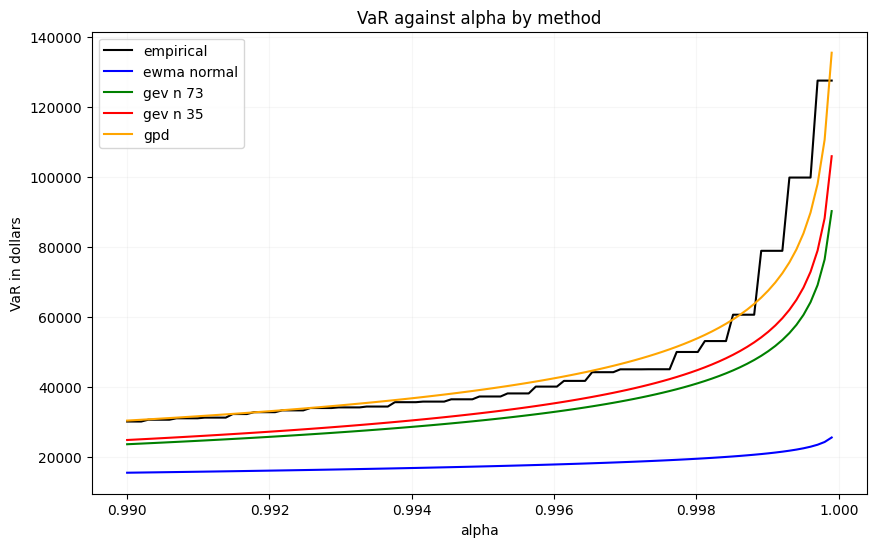

empirical      127652.20
ewma normal     25667.50
gev n 73        90353.40
gev n 35       106041.45
gpd            135614.30
dtype: float64
highest gpd


In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(alphas, var_emp, color="black", label="empirical")
plt.plot(alphas, var_norm, color="blue", label="ewma normal")
plt.plot(alphas, var_gev73, color="green", label="gev n 73")
plt.plot(alphas, var_gev35, color="red", label="gev n 35")
plt.plot(alphas, var_gpd, color="orange", label="gpd")
plt.xlabel("alpha")
plt.ylabel("VaR in dollars")
plt.title("VaR against alpha by method")
plt.legend()
plt.grid(alpha=0.1)
plt.show()

answers = pd.Series({"empirical": var_emp[-1], "ewma normal": var_norm[-1],
                     "gev n 73": var_gev73[-1], "gev n 35": var_gev35[-1], "gpd": var_gpd[-1]})
print(answers.round(2))
print("highest", answers.idxmax())

At alpha equal to 0.9999 the generalized Pareto fit gives 135,614 dollars, the empirical
distribution gives 127,652, the block maximum fit gives 106,041 with 35 day blocks and 90,353
with 73 day blocks, and the EWMA normal gives 25,668. The generalized Pareto estimate is the
highest of the five. The normal figure sits far below the rest because it is a one day estimate made when volatility
was low and because the normal tail runs out quickly, with 0.9999 sitting only 3.72 standard
deviations out. The empirical curve goes flat above roughly 0.9996 since it has no observation
left to return beyond the worst day in the sample. The two extreme value estimates do differ meaningfully. The generalized Pareto number comes in
about 28 percent above the 73 day block result and about 50 percent above the 35 day one, which
follows from the fitted shape parameters of 0.266 against 0.214 and 0.182. The generalized Pareto
fit uses all 127 days above the threshold while the block maximum fits keep only the worst day in
each block, so I would put more weight on it.